# 01 | Data Inventory and Temporal Feasibility Audit

This notebook explores the six raw source datasets before preprocessing. It documents their structure, checks basic data quality and key relationships, and investigates whether the available observations support a **30-minute-ahead Level of Service (LOS) target**.

The notebook is diagnostic: it does not modify the original CSV files or create the final modeling dataset. Its findings are used to guide the preprocessing and integration steps in the next notebook.

## 1. Environment and Source Data Loading

Locate the project root, identify `data/raw`, verify that all expected CSV files are present, and load the source tables into memory. The original files remain unchanged.

In [1]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Find project root automatically
PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "data" / "raw").exists():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise FileNotFoundError("Cannot find project root")
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DIR = PROJECT_ROOT / "data" / "raw"

print("Project root:", PROJECT_ROOT)
print("Raw data directory:", RAW_DIR)
print("Directory exists:", RAW_DIR.exists())


Project root: c:\CODE_PROJECTS\KHAI PHA DU LIEU\FinalTermProject\hcmc-traffic-los-forecasting
Raw data directory: c:\CODE_PROJECTS\KHAI PHA DU LIEU\FinalTermProject\hcmc-traffic-los-forecasting\data\raw
Directory exists: True


In [2]:

# Define original dataset files
DATA_FILES = {
    "train": "train.csv",
    "segment_status": "segment_status.csv",
    "segments": "segments.csv",
    "streets": "streets.csv",
    "nodes": "nodes.csv",
    "weather": "weather_hcm.csv"
}

# Check missing files
missing_files = [
    filename
    for filename in DATA_FILES.values()
    if not (RAW_DIR / filename).exists()
]

if missing_files:
    raise FileNotFoundError(
        f"Missing files: {missing_files}"
    )

# Load datasets
data = {
    name: pd.read_csv(
        RAW_DIR / filename,
        low_memory=False
    )
    for name, filename in DATA_FILES.items()
}

print("ALL DATASETS LOADED SUCCESSFULLY!")


ALL DATASETS LOADED SUCCESSFULLY!


## 2. Dataset Inventory and Structure

Review the row and column counts, missing-cell totals, duplicate-row counts, column names, and inferred data types for each source table. This establishes the baseline structure before any transformation.

In [3]:

summary = []

for name, df in data.items():
    summary.append({
        "Dataset": name,
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Missing Cells": df.isna().sum().sum(),
        "Duplicate Rows": df.duplicated().sum(),
        "Memory (MB)": round(
            df.memory_usage(deep=True).sum() / 1024**2,
            2
        )
    })

summary_df = pd.DataFrame(summary)

display(summary_df)


,Dataset,Rows,Columns,Missing Cells,Duplicate Rows,Memory (MB)
0,train,33441,18,28496,0,6.10
1,segment_status,90938,4,0,0,4.86
2,segments,84633,11,74914,0,13.08
3,streets,5553,5,6171,0,0.32
4,nodes,577967,3,0,0,13.23
5,weather,7056,8,0,0,0.54


In [4]:

for name, df in data.items():
    print(f"\nDATASET: {name.upper()}\n")

    print("Columns:")
    for col in df.columns:
        print(f" - {col}")

    print("\nData types:")
    print(df.dtypes)



DATASET: TRAIN

Columns:
 - _id
 - segment_id
 - date
 - weekday
 - period
 - LOS
 - s_node_id
 - e_node_id
 - length
 - street_id
 - max_velocity
 - street_level
 - street_name
 - street_type
 - long_snode
 - lat_snode
 - long_enode
 - lat_enode

Data types:
_id               int64
segment_id        int64
date                str
weekday           int64
period              str
LOS                 str
s_node_id         int64
e_node_id         int64
length            int64
street_id         int64
max_velocity    float64
street_level      int64
street_name         str
street_type         str
long_snode      float64
lat_snode       float64
long_enode      float64
lat_enode       float64
dtype: object

DATASET: SEGMENT_STATUS

Columns:
 - _id
 - updated_at
 - segment_id
 - velocity

Data types:
_id           int64
updated_at      str
segment_id    int64
velocity      int64
dtype: object

DATASET: SEGMENTS

Columns:
 - _id
 - created_at
 - updated_at
 - s_node_id
 - e_node_id
 - length
 - s

## 3. Missing Values and Key Integrity

Quantify missing values by column and test candidate primary or composite keys. These checks help distinguish expected sparsity from duplicate-key problems that could affect later joins.

In [5]:

# Detailed missing value analysis

missing_reports = []

for name, df in data.items():
    for col in df.columns:
        missing_count = df[col].isna().sum()

        missing_reports.append({
            "Dataset": name,
            "Column": col,
            "Missing_Count": missing_count,
            "Missing_Percent": round(
                missing_count / len(df) * 100, 2
            )
        })

missing_df = pd.DataFrame(missing_reports)

missing_df = missing_df.sort_values(
    by=["Dataset", "Missing_Percent"],
    ascending=[True, False]
)

display(
    missing_df[missing_df["Missing_Count"] > 0]
    .reset_index(drop=True)
)


,Dataset,Column,Missing_Count,Missing_Percent
0,segments,max_velocity,74762,88.34
1,segments,street_name,152,0.18
2,streets,max_velocity,4566,82.23
3,streets,name,1605,28.90
4,train,max_velocity,28495,85.21
5,train,street_name,1,0.00


In [6]:

key_candidates = {
    "train": ["segment_id", "date", "period"],
    "segment_status": ["segment_id", "updated_at"],
    "segments": ["_id"],
    "streets": ["_id"],
    "nodes": ["_id"],
    "weather": ["time"]
}

key_results = []

for name, keys in key_candidates.items():
    df = data[name]

    duplicate_count = df.duplicated(
        subset=keys
    ).sum()

    key_results.append({
        "Dataset": name,
        "Candidate_Key": " + ".join(keys),
        "Total_Rows": len(df),
        "Unique_Key_Count": df[keys].drop_duplicates().shape[0],
        "Duplicate_Key_Rows": duplicate_count,
        "Is_Unique": duplicate_count == 0
    })

key_df = pd.DataFrame(key_results)

display(key_df)


,Dataset,Candidate_Key,Total_Rows,Unique_Key_Count,Duplicate_Key_Rows,Is_Unique
0,train,segment_id + date + period,33441,33441,0,True
1,segment_status,segment_id + updated_at,90938,90938,0,True
2,segments,_id,84633,84633,0,True
3,streets,_id,5553,5553,0,True
4,nodes,_id,577967,577967,0,True
5,weather,time,7056,7056,0,True


## 4. Traffic Characteristics and Source Time Fields

Inspect the original LOS class distribution and traffic-velocity values, then review representative time fields from the traffic, segment-status, and weather datasets. These checks provide context for later temporal alignment.

,Count,Percentage
LOS,,
A,13278,39.71
B,4700,14.05
C,3839,11.48
D,3707,11.09
E,3828,11.45
F,4089,12.23


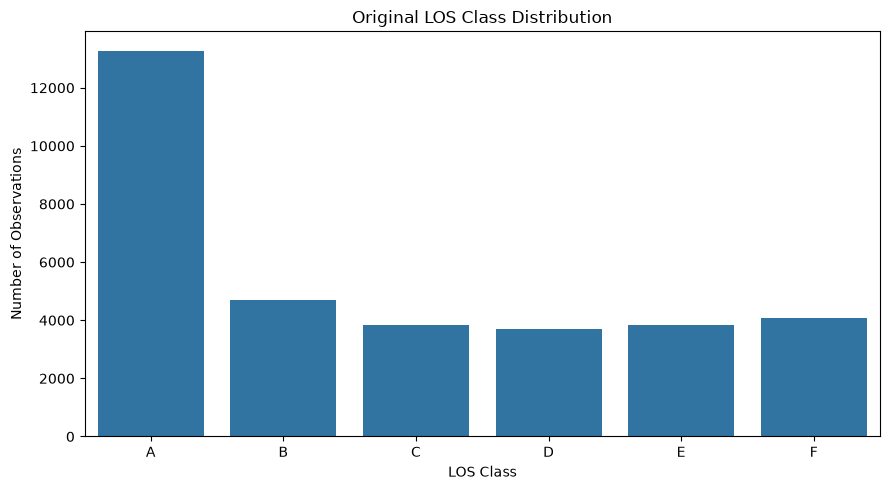

In [7]:

# LOS class distribution

los_counts = (
    data["train"]["LOS"]
    .value_counts(dropna=False)
    .sort_index()
)

los_summary = pd.DataFrame({
    "Count": los_counts,
    "Percentage": (
        los_counts / len(data["train"]) * 100
    ).round(2)
})

display(los_summary)

# Visualize
plt.figure(figsize=(9, 5))

sns.barplot(
    x=los_summary.index.astype(str),
    y=los_summary["Count"]
)

plt.title("Original LOS Class Distribution")
plt.xlabel("LOS Class")
plt.ylabel("Number of Observations")
plt.tight_layout()
plt.show()


Velocity statistics:


,velocity
count,90938.000000
mean,20.754844
std,19.567112
min,0.000000
1%,1.000000
5%,1.000000
25%,2.000000
50%,17.000000
75%,34.000000
95%,50.000000



Zero velocity: 448
Negative velocity: 0
Velocity above 100: 151


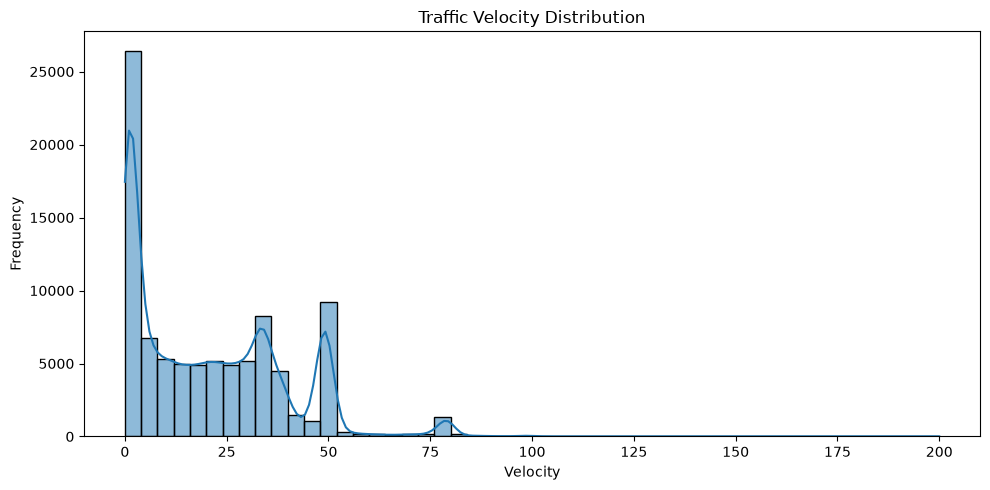

In [8]:

velocity = data["segment_status"]["velocity"]

print("Velocity statistics:")
display(velocity.describe(
    percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
).to_frame())

print("\nZero velocity:", (velocity == 0).sum())
print("Negative velocity:", (velocity < 0).sum())
print("Velocity above 100:", (velocity > 100).sum())

plt.figure(figsize=(10, 5))

sns.histplot(
    velocity,
    bins=50,
    kde=True
)

plt.title("Traffic Velocity Distribution")
plt.xlabel("Velocity")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


In [9]:
print("[TRAIN TIME]")

display(
    data["train"][
        ["date", "weekday", "period", "LOS"]
    ].head(10)
)

print("\n[SEGMENT STATUS TIME]")

display(
    data["segment_status"][
        ["updated_at", "segment_id", "velocity"]
    ].head(10)
)

print("\n[WEATHER TIME]")

display(
    pd.concat([
        data["weather"].head(5),
        data["weather"].tail(5)
    ])
)

[TRAIN TIME]


,date,weekday,period,LOS
0,2021-04-16,4,period_0_30,A
1,2020-08-02,6,period_23_30,C
2,2020-08-03,0,period_0_00,D
3,2021-03-09,1,period_9_30,B
4,2021-03-23,1,period_9_30,B
5,2020-08-02,6,period_23_30,D
6,2020-08-03,0,period_0_00,E
7,2020-08-02,6,period_23_30,E
8,2020-08-03,0,period_0_00,C
9,2020-09-11,4,period_0_30,A



[SEGMENT STATUS TIME]


,updated_at,segment_id,velocity
0,2020-07-03T14:55:31.869Z,24845,20
1,2020-07-03T15:02:56.048Z,33923,10
2,2020-07-04T08:15:52.696Z,33824,5
3,2020-07-04T08:15:59.903Z,33824,5
4,2020-07-04T08:16:08.201Z,33824,5
5,2020-07-04T08:16:11.070Z,33824,5
6,2020-07-04T08:16:18.512Z,33824,5
7,2020-07-04T08:16:21.798Z,33824,5
8,2020-07-04T08:16:24.746Z,33824,5
9,2020-07-04T08:16:27.606Z,33824,5



[WEATHER TIME]


,time,temperature_2m,relative_humidity_2m,precipitation,rain,weather_code,wind_speed_10m,cloud_cover
0,2020-07-03T00:00,25.6,96,0.8,0.8,53,6.1,99
1,2020-07-03T01:00,25.6,96,1.2,1.2,55,4.8,98
2,2020-07-03T02:00,25.3,96,1.1,1.1,55,5.7,97
3,2020-07-03T03:00,25.1,97,1.3,1.3,61,5.9,100
4,2020-07-03T04:00,25.1,97,0.5,0.5,53,6.4,100
7051,2021-04-22T19:00,27.8,88,0.2,0.2,51,5.2,100
7052,2021-04-22T20:00,27.6,89,0.0,0.0,3,5.5,90
7053,2021-04-22T21:00,26.2,91,2.0,2.0,61,8.4,100
7054,2021-04-22T22:00,25.8,92,2.1,2.1,61,1.5,96
7055,2021-04-22T23:00,25.6,94,0.3,0.3,51,3.3,97


## 5. Relational Integrity and Segment-Status Sampling

Check whether the expected foreign-key relationships resolve across the source tables. Then examine the frequency and time gaps of segment-status observations to understand how densely each road segment is sampled.

In [10]:

# Candidate foreign-key relationships

relationships = [
    ("train", "segment_id", "segments", "_id"),
    ("segment_status", "segment_id", "segments", "_id"),
    ("segments", "street_id", "streets", "_id"),
    ("segments", "s_node_id", "nodes", "_id"),
    ("segments", "e_node_id", "nodes", "_id"),
]

fk_results = []

for child_name, child_col, parent_name, parent_col in relationships:

    child = data[child_name][child_col].dropna()
    parent_ids = set(data[parent_name][parent_col].dropna())

    unmatched = ~child.isin(parent_ids)

    fk_results.append({
        "Relationship": f"{child_name}.{child_col} -> {parent_name}.{parent_col}",
        "Child_Rows": len(child),
        "Unmatched_Rows": int(unmatched.sum()),
        "Unmatched_Percent": round(unmatched.mean() * 100, 2)
    })

fk_df = pd.DataFrame(fk_results)

display(fk_df)


,Relationship,Child_Rows,Unmatched_Rows,Unmatched_Percent
0,train.segment_id -> segments._id,33441,0,0.0
1,segment_status.segment_id -> segments._id,90938,0,0.0
2,segments.street_id -> streets._id,84633,0,0.0
3,segments.s_node_id -> nodes._id,84633,0,0.0
4,segments.e_node_id -> nodes._id,84633,0,0.0


In [11]:

status = data["segment_status"].copy()

status["updated_at_utc"] = pd.to_datetime(
    status["updated_at"],
    utc=True,
    errors="coerce"
)

status = status.sort_values(
    ["segment_id", "updated_at_utc"]
)

status["time_gap_minutes"] = (
    status.groupby("segment_id")["updated_at_utc"]
    .diff()
    .dt.total_seconds() / 60
)

print("Overall time gap statistics:")
display(
    status["time_gap_minutes"].describe(
        percentiles=[0.25, 0.5, 0.75, 0.9, 0.95]
    )
)

print("\nObservations per segment:")
display(
    status.groupby("segment_id")
    .size()
    .describe()
)

print("\nTime range:")
print(status["updated_at_utc"].min())
print(status["updated_at_utc"].max())


Overall time gap statistics:


count     80911.000000
mean       4736.001892
std       24881.883186
min           0.000050
25%           0.211342
50%           2.997250
75%           6.685158
90%        2258.637133
95%       15909.657725
max      381380.888633
Name: time_gap_minutes, dtype: float64


Observations per segment:


count    10027.000000
mean         9.069313
std         48.652879
min          1.000000
25%          1.000000
50%          5.000000
75%         10.000000
max       2150.000000
dtype: float64


Time range:
2020-07-03 14:55:31.869000+00:00
2021-04-22 06:53:27.300000+00:00


## 6. Future LOS Feasibility and Timezone Interpretation

Reconstruct observation timestamps from `date` and `period`, then look for an exact LOS observation on the same segment 30 minutes later. Compare UTC and Ho Chi Minh City (HCMC) timezone interpretations when matching train observations to status timestamps.

In [12]:

import re

train_time = data["train"][
    ["segment_id", "date", "period", "LOS"]
].copy()

# Extract hour and minute from period
parts = train_time["period"].str.extract(
    r"^period_(\d{1,2})_(\d{2})$"
)

train_time["hour"] = pd.to_numeric(parts[0], errors="coerce")
train_time["minute"] = pd.to_numeric(parts[1], errors="coerce")

# Build candidate local/naive observation timestamp
train_time["observation_time"] = pd.to_datetime(
    train_time["date"].astype(str)
    + " "
    + train_time["hour"].astype("Int64").astype(str).str.zfill(2)
    + ":"
    + train_time["minute"].astype("Int64").astype(str).str.zfill(2),
    errors="coerce"
)

# Target timestamp = observation timestamp + 30 minutes
train_time["target_time"] = (
    train_time["observation_time"]
    + pd.Timedelta(minutes=30)
)

# Build future label lookup
future_labels = train_time[
    ["segment_id", "observation_time", "LOS"]
].rename(columns={
    "observation_time": "target_time",
    "LOS": "target_los_30m"
})

# Exact matching by segment and target time
target_check = train_time.merge(
    future_labels,
    on=["segment_id", "target_time"],
    how="left",
    indicator=True
)

target_check["has_future_label"] = (
    target_check["_merge"] == "both"
)

print("Total original observations:", len(target_check))
print(
    "Observations with exact future LOS:",
    target_check["has_future_label"].sum()
)

print(
    "Future LOS coverage (%):",
    round(
        target_check["has_future_label"].mean() * 100,
        2
    )
)

display(
    target_check["has_future_label"]
    .value_counts()
    .rename("Count")
    .to_frame()
)


Total original observations: 33441
Observations with exact future LOS: 7898
Future LOS coverage (%): 23.62


,Count
has_future_label,
False,25543
True,7898


In [13]:

# Prepare status timestamps in UTC
status_time = data["segment_status"][
    ["segment_id", "updated_at"]
].copy()

status_time["status_time"] = pd.to_datetime(
    status_time["updated_at"],
    utc=True,
    errors="coerce"
)

status_time = status_time.dropna(
    subset=["status_time"]
)

def compare_timezone_hypothesis(train_df, status_df, time_col, label):

    left = train_df[
        ["segment_id", time_col]
    ].dropna().rename(
        columns={time_col: "train_time"}
    )

    right = status_df[
        ["segment_id", "status_time"]
    ]

    left = left.sort_values("train_time")
    right = right.sort_values("status_time")

    matched = pd.merge_asof(
        left,
        right,
        by="segment_id",
        left_on="train_time",
        right_on="status_time",
        direction="nearest",
        tolerance=pd.Timedelta("30min")
    )

    gap = (
        matched["train_time"] - matched["status_time"]
    ).abs().dt.total_seconds() / 60

    return {
        "Hypothesis": label,
        "Matched_Rows": int(gap.notna().sum()),
        "Matched_Percent": round(gap.notna().mean() * 100, 2),
        "Median_Gap_Minutes": gap.median(),
        "P90_Gap_Minutes": gap.quantile(0.90)
    }

timezone_test = train_time[
    ["segment_id", "observation_time"]
].copy()

timezone_test["time_as_utc"] = (
    timezone_test["observation_time"]
    .dt.tz_localize("UTC")
)

timezone_test["time_as_hcmc"] = (
    timezone_test["observation_time"]
    .dt.tz_localize("Asia/Ho_Chi_Minh")
    .dt.tz_convert("UTC")
)

timezone_results = pd.DataFrame([
    compare_timezone_hypothesis(
        timezone_test,
        status_time,
        "time_as_utc",
        "Train interpreted as UTC"
    ),
    compare_timezone_hypothesis(
        timezone_test,
        status_time,
        "time_as_hcmc",
        "Train interpreted as HCMC local time"
    )
])

display(timezone_results)


,Hypothesis,Matched_Rows,Matched_Percent,Median_Gap_Minutes,P90_Gap_Minutes
0,Train interpreted as UTC,33441,100.00,13.611400,26.526583
1,Train interpreted as HCMC local time,260,0.78,12.828683,22.244950


## 7. Past-Only Velocity Availability and Target Coverage

Match each train observation to the latest available segment-status record at or before that observation. Measure how much velocity information is available at different freshness thresholds, and inspect the class distribution and current-versus-future LOS relationship among observations with a valid 30-minute target.

In [14]:

# 1. Prepare train observation timestamps
train_obs = train_time[
    ["segment_id", "observation_time"]
].copy()

train_obs = train_obs.dropna(
    subset=["observation_time"]
)

train_obs["observation_time_utc"] = (
    train_obs["observation_time"]
    .dt.tz_localize("UTC")
)

# 2. Prepare traffic status
status_obs = data["segment_status"][
    ["segment_id", "updated_at", "velocity"]
].copy()

status_obs["status_time_utc"] = pd.to_datetime(
    status_obs["updated_at"],
    utc=True,
    errors="coerce"
)

status_obs = status_obs.dropna(
    subset=["status_time_utc"]
)

# 3. Sort globally by time
train_obs = train_obs.sort_values(
    "observation_time_utc"
)

status_obs = status_obs.sort_values(
    "status_time_utc"
)

# 4. Backward-only matching
velocity_match = pd.merge_asof(
    train_obs,
    status_obs,
    left_on="observation_time_utc",
    right_on="status_time_utc",
    by="segment_id",
    direction="backward"
)

# 5. Calculate data freshness
velocity_match["velocity_age_minutes"] = (
    velocity_match["observation_time_utc"]
    - velocity_match["status_time_utc"]
).dt.total_seconds() / 60

# 6. Summarize coverage
thresholds = [5, 15, 30, 60, 180, 1440]

velocity_coverage = []

for minutes in thresholds:

    valid = (
        velocity_match["velocity_age_minutes"]
        .notna()
        & (
            velocity_match["velocity_age_minutes"]
            <= minutes
        )
    )

    velocity_coverage.append({
        "Max_Age_Minutes": minutes,
        "Matched_Rows": int(valid.sum()),
        "Coverage_Percent": round(
            valid.mean() * 100, 2
        )
    })

velocity_coverage_df = pd.DataFrame(
    velocity_coverage
)

display(velocity_coverage_df)

print("\nVelocity age statistics:")
display(
    velocity_match["velocity_age_minutes"].describe(
        percentiles=[0.25, 0.5, 0.75, 0.9, 0.95]
    )
)


,Max_Age_Minutes,Matched_Rows,Coverage_Percent
0,5,4348,13.00
1,15,5703,17.05
2,30,7898,23.62
3,60,9597,28.70
4,180,10778,32.23
5,1440,14337,42.87



Velocity age statistics:


count     23414.000000
mean      16348.811976
std       44150.167959
min           0.000883
25%          15.974588
50%         512.400225
75%        7114.227483
90%       35961.553175
95%      133335.200606
max      381363.181233
Name: velocity_age_minutes, dtype: float64

In [15]:

valid_targets = target_check[
    target_check["has_future_label"]
].copy()

target_distribution = (
    valid_targets["target_los_30m"]
    .value_counts()
    .sort_index()
    .rename("Count")
    .to_frame()
)

target_distribution["Percentage"] = (
    target_distribution["Count"]
    / len(valid_targets) * 100
).round(2)

display(target_distribution)

print("Valid target samples:", len(valid_targets))

print(
    "Unique road segments:",
    valid_targets["segment_id"].nunique()
)

print(
    "Target time range:",
    valid_targets["target_time"].min(),
    "to",
    valid_targets["target_time"].max()
)

# Compare current LOS and future LOS
display(
    pd.crosstab(
        valid_targets["LOS"],
        valid_targets["target_los_30m"],
        margins=True
    )
)


,Count,Percentage
target_los_30m,,
A,2591,32.81
B,1167,14.78
C,837,10.60
D,1740,22.03
E,1100,13.93
F,463,5.86


Valid target samples: 7898
Unique road segments: 4607
Target time range: 2020-07-04 08:30:00 to 2021-04-22 06:30:00


target_los_30m,A,B,C,D,E,F,All
LOS,,,,,,,
A,2559,17,40,83,53,10,2762
B,17,1089,64,95,63,2,1330
C,4,37,255,531,304,10,1141
D,0,7,112,240,135,8,502
E,1,12,246,561,376,22,1218
F,10,5,120,230,169,411,945
All,2591,1167,837,1740,1100,463,7898


In [16]:

gaps = status["time_gap_minutes"].dropna()

bins = [
    0, 1, 5, 15, 30, 60, 360, 1440, np.inf
]

labels = [
    "<= 1 min",
    "1-5 min",
    "5-15 min",
    "15-30 min",
    "30-60 min",
    "1-6 hours",
    "6-24 hours",
    "> 24 hours"
]

gap_groups = pd.cut(
    gaps,
    bins=bins,
    labels=labels,
    include_lowest=True
)

gap_summary = (
    gap_groups.value_counts(sort=False)
    .rename("Count")
    .to_frame()
)

gap_summary["Percentage"] = (
    gap_summary["Count"] / len(gaps) * 100
).round(2)

display(gap_summary)


,Count,Percentage
time_gap_minutes,,
<= 1 min,26880,33.22
1-5 min,33676,41.62
5-15 min,399,0.49
15-30 min,2279,2.82
30-60 min,3543,4.38
1-6 hours,2172,2.68
6-24 hours,2787,3.44
> 24 hours,9175,11.34


In [17]:

# Merge future target information with past-only velocity
velocity_cols = velocity_match[
    [
        "segment_id",
        "observation_time",
        "velocity",
        "status_time_utc",
        "velocity_age_minutes"
    ]
].copy()

analysis_df = target_check.merge(
    velocity_cols,
    on=["segment_id", "observation_time"],
    how="left",
    validate="one_to_one"
)

# Keep only samples with valid future LOS
valid_analysis = analysis_df[
    analysis_df["has_future_label"]
].copy()

print("Valid target samples:", len(valid_analysis))

# Check velocity availability at different freshness thresholds
thresholds = [5, 15, 30, 60, 180, 1440]

intersection_results = []

for minutes in thresholds:

    mask = (
        valid_analysis["velocity_age_minutes"].notna()
        & (
            valid_analysis["velocity_age_minutes"]
            <= minutes
        )
    )

    intersection_results.append({
        "Max_Velocity_Age_Minutes": minutes,
        "Samples_With_Velocity": int(mask.sum()),
        "Coverage_Of_Valid_Targets": round(
            mask.mean() * 100, 2
        )
    })

intersection_df = pd.DataFrame(
    intersection_results
)

display(intersection_df)

# Inspect samples without fresh velocity
print(
    "\nTarget samples without velocity within 30 minutes:",
    (
        valid_analysis["velocity_age_minutes"].isna()
        | (
            valid_analysis["velocity_age_minutes"] > 30
        )
    ).sum()
)


Valid target samples: 7898


,Max_Velocity_Age_Minutes,Samples_With_Velocity,Coverage_Of_Valid_Targets
0,5,375,4.75
1,15,833,10.55
2,30,1520,19.25
3,60,2023,25.61
4,180,2269,28.73
5,1440,3290,41.66



Target samples without velocity within 30 minutes: 6378


## 8. Weather Coverage and Weekday Convention

Assess whether each train observation can be matched to a recent weather record using a backward-only time join. Finally, compare possible weekday numbering conventions against the source `weekday` field to identify the interpretation most consistent with the data.

In [18]:

weather = data["weather"].copy()

# Convert HCMC local time to UTC
weather["weather_time_utc"] = (
    pd.to_datetime(weather["time"], errors="coerce")
    .dt.tz_localize("Asia/Ho_Chi_Minh")
    .dt.tz_convert("UTC")
)

# Prepare train observation timestamps
weather_train = train_time[
    ["segment_id", "observation_time"]
].copy()

weather_train = weather_train.dropna(
    subset=["observation_time"]
)

weather_train["observation_time_utc"] = (
    weather_train["observation_time"]
    .dt.tz_localize("UTC")
)

# Sort for backward as-of join
weather_train = weather_train.sort_values(
    "observation_time_utc"
)

weather = weather.sort_values(
    "weather_time_utc"
)

# Use the latest weather observation at or before t
weather_match = pd.merge_asof(
    weather_train,
    weather,
    left_on="observation_time_utc",
    right_on="weather_time_utc",
    direction="backward",
    tolerance=pd.Timedelta("60min")
)

weather_match["weather_age_minutes"] = (
    weather_match["observation_time_utc"]
    - weather_match["weather_time_utc"]
).dt.total_seconds() / 60

print("Total train observations:", len(weather_match))

print(
    "Weather matched:",
    weather_match["weather_time_utc"].notna().sum()
)

print(
    "Weather coverage (%):",
    round(
        weather_match["weather_time_utc"].notna().mean() * 100,
        2
    )
)

print("\nWeather age statistics:")

display(
    weather_match["weather_age_minutes"].describe()
)


Total train observations: 33441
Weather matched: 33441
Weather coverage (%): 100.0

Weather age statistics:


count    33441.000000
mean        15.182560
std         14.999113
min          0.000000
25%          0.000000
50%         30.000000
75%         30.000000
max         30.000000
Name: weather_age_minutes, dtype: float64

In [19]:

weekday_audit = data["train"][
    ["date", "period", "weekday"]
].copy()

# Parse period
parts = weekday_audit["period"].str.extract(
    r"^period_(\d{1,2})_(\d{2})$"
)

weekday_audit["hour"] = pd.to_numeric(
    parts[0], errors="coerce"
)

weekday_audit["minute"] = pd.to_numeric(
    parts[1], errors="coerce"
)

# Construct naive timestamp
weekday_audit["time_naive"] = pd.to_datetime(
    weekday_audit["date"].astype(str)
    + " "
    + weekday_audit["hour"].astype("Int64").astype(str).str.zfill(2)
    + ":"
    + weekday_audit["minute"].astype("Int64").astype(str).str.zfill(2),
    errors="coerce"
)

# Candidate weekday interpretations
weekday_audit["weekday_utc_mon0"] = (
    weekday_audit["time_naive"].dt.day_of_week
)

weekday_audit["weekday_utc_mon1"] = (
    weekday_audit["time_naive"].dt.day_of_week + 1
)

weekday_audit["weekday_utc_sun0"] = (
    (weekday_audit["time_naive"].dt.day_of_week + 1) % 7
)

# Interpret timestamp as UTC, then convert to HCMC
time_utc = weekday_audit["time_naive"].dt.tz_localize("UTC")

time_local = time_utc.dt.tz_convert(
    "Asia/Ho_Chi_Minh"
)

weekday_audit["weekday_local_mon0"] = (
    time_local.dt.day_of_week
)

weekday_audit["weekday_local_mon1"] = (
    time_local.dt.day_of_week + 1
)

weekday_audit["weekday_local_sun0"] = (
    (time_local.dt.day_of_week + 1) % 7
)

# Compare source weekday with candidate conventions
candidate_columns = [
    "weekday_utc_mon0",
    "weekday_utc_mon1",
    "weekday_utc_sun0",
    "weekday_local_mon0",
    "weekday_local_mon1",
    "weekday_local_sun0"
]

weekday_results = []

for col in candidate_columns:

    valid = weekday_audit[
        ["weekday", col]
    ].dropna()

    weekday_results.append({
        "Interpretation": col,
        "Matching_Rows": int(
            (valid["weekday"] == valid[col]).sum()
        ),
        "Matching_Percent": round(
            (valid["weekday"] == valid[col]).mean() * 100,
            2
        )
    })

display(
    pd.DataFrame(weekday_results)
    .sort_values("Matching_Percent", ascending=False)
)

print("\nSource weekday values:")
display(
    weekday_audit["weekday"]
    .value_counts()
    .sort_index()
)

print("\nInvalid period rows:")
print(
    weekday_audit[
        weekday_audit["time_naive"].isna()
    ].shape[0]
)


,Interpretation,Matching_Rows,Matching_Percent
0,weekday_utc_mon0,33441,100.00
3,weekday_local_mon0,29121,87.08
1,weekday_utc_mon1,0,0.00
2,weekday_utc_sun0,0,0.00
4,weekday_local_mon1,0,0.00
5,weekday_local_sun0,0,0.00



Source weekday values:


weekday
0    8112
1    4254
2    3503
3    3658
4    2011
5    4207
6    7696
Name: count, dtype: int64


Invalid period rows:
0
